# LLM: Fine-Tuning Hands-On on a CPU (SFT, LoRA from scratch, forgetting, DPO)

> **Who is this for:** you know what a language model is ([`00_start_here_how_llms_work`](00_start_here_how_llms_work.ipynb)) and have read the overview of fine-tuning methods in [`03_fine_tuning/01_fine_tuning`](03_fine_tuning/01_fine_tuning.ipynb), which assumes a GPU. Here you **run every step yourself on a laptop CPU**, on a tiny model, so you can see exactly what each method does to the weights and the outputs.
>
> **What you will learn:**
> - How a small **base model** is pre-trained, and how to measure it (perplexity)
> - **Instruction data and chat templates**, and **loss masking**: why prompt tokens get the label −100 (and an assert that proves we did it right)
> - **Full supervised fine-tuning (SFT)** on a synthetic instruction set, with exact-match evaluation before and after
> - **LoRA from scratch**: the A and B matrices, rank, α scaling, merge and unmerge; a rank sweep comparing quality and trainable parameters with full fine-tuning
> - **Catastrophic forgetting**: base-text perplexity before and after, and mitigation by **replay mixing**
> - **DPO from scratch** on preference pairs: the reference-model trick, a β sweep, chosen vs rejected log-probability margins
> - **Overfitting, early stopping and checkpointing** with a validation set
> - **[optional]** the same ideas with Hugging Face `peft` and `trl` on a tiny cached model
>
> **Prerequisites:** [PyTorch from zero](../05_Deep_Learning/00_start_here_pytorch_from_zero.ipynb), [how LLMs work](00_start_here_how_llms_work.ipynb) (tokens, next-token prediction, the tiny GPT), [transformer architecture](../05_Deep_Learning/05_transformers_architecture.ipynb). Optional: [advanced PEFT](../05_Deep_Learning/12_advanced_peft.ipynb) and [alignment techniques](12_alignment_techniques.ipynb).
>
> **Time needed:** about 3 hours.
>
> **Runs on:** CPU only, no API key, no internet, no download. All data is generated in the notebook. The model has about 110 thousand parameters (the same tiny-GPT family as [`00_start_here`](00_start_here_how_llms_work.ipynb), sized so every experiment trains in well under a minute). Expect about 5–8 minutes for the whole notebook. The optional `peft`/`trl` section uses a tiny test model only if it is already in your Hugging Face cache.
>
> **Optional track:** this notebook is part of the university-level fundamentals track; recommended for BS/MS AI students and interview prep.

## Explained simply

A **base** language model has read a lot of text and is good at continuing it, but it does not know how to *follow instructions*. **Fine-tuning** means training it a little more on examples of exactly the behaviour you want, such as "question → answer" pairs. It is like a new employee who already speaks the language well (pre-training) and then gets two days of on-the-job training on your company's forms (fine-tuning).

Two everyday examples. A pianist who already plays classical music learns jazz much faster than a beginner, but if they practise only jazz for months they may get rusty at Bach; that rust is **catastrophic forgetting**. A teacher marking essays does not write a score from scratch; they say "this one is better than that one". Training a model from such *comparisons* is **preference optimisation** (DPO).

**LoRA** is a trick to fine-tune cheaply: instead of changing all the weights, you freeze them and learn a small "correction" made of two thin matrices. Think of sticky notes on a textbook: the book stays the same, and the notes change how you read it.

**Tiny example.** Our tiny model will learn instructions such as `date: 2026-10-27` → `27/10/2026` and `swap: frog, cow` → `cow, frog`. Before fine-tuning it answers none of our 100 test instructions correctly; after about 20 seconds of fine-tuning it answers most of them. With LoRA it trains only a few thousand of its ~110 thousand numbers (9,216 at rank 4, about 8%) and still learns part of the tasks.

**In one line**

| Concept | Simple meaning | Where you see it in real life/AI |
|---|---|---|
| Supervised fine-tuning (SFT) | show the model many "instruction → good answer" examples | turning a base model into a chat assistant |
| LoRA | learn a small add-on instead of changing the whole model | cheap custom models on one GPU; many adapters served from one base model |
| DPO | teach the model to prefer the better of two answers | aligning chatbots with human preferences (helpful, polite, safe) |

### How this notebook is different from `03_fine_tuning/01` and `05_Deep_Learning/12`
[`03_fine_tuning/01`](03_fine_tuning/01_fine_tuning.ipynb) explains SFT, LoRA, QLoRA, DPO and RLHF with library code meant for a GPU. [`05_Deep_Learning/12_advanced_peft`](../05_Deep_Learning/12_advanced_peft.ipynb) surveys PEFT variants. Here everything is **implemented from scratch and actually trained**, so you can measure the effects (exact match, perplexity, margins), not just read about them.

## Table of contents
1. A tiny base model, pre-trained in the notebook
2. Instruction data, chat templates and loss masking
3. Full supervised fine-tuning (SFT)
4. LoRA from scratch
5. Catastrophic forgetting and replay mixing
6. DPO from scratch
7. Overfitting, early stopping and checkpointing
8. [optional] The same with `peft` and `trl`
9. Summary table
10. How this connects to modern AI
11. Recap, practice problems, further reading

In [1]:
# Standard setup used throughout this notebook
import math, random, time, copy, os, sys, tempfile, shutil
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch, torch.nn as nn, torch.nn.functional as F

torch.set_num_threads(2)            # small and CPU-friendly; never use more than 2 threads on a shared machine
SEED = 0
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)

PALETTE = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300", "#6250d6", "#e34948"]
plt.rcParams.update({"axes.prop_cycle": plt.cycler(color=PALETTE), "lines.linewidth": 2,
                     "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.alpha": 0.3, "axes.titleweight": "bold", "figure.dpi": 100})
pd.set_option("display.width", 140); pd.set_option("display.max_colwidth", 60)
NOTEBOOK_START = time.time()
print("torch", torch.__version__, "| threads", torch.get_num_threads())

torch 2.12.1+cpu | threads 2


## 1. A tiny base model, pre-trained in the notebook

> 💬 **In plain English:** we first teach a tiny model to write simple English, so we have a 'base model' to fine-tune.

We need a **base model** that knows some language but no instructions. Downloading one is not allowed here, so we pre-train our own on generated "simple English": short sentences about animals, people, numbers and dates, e.g. *"on 2017-02-12 omar met ana, that is 12/02/2017."* The vocabulary is **characters** plus four **special tokens** that the base model never sees during pre-training:

| Token | Role |
|---|---|
| `<user>` | start of the user's turn |
| `<asst>` | start of the assistant's turn |
| `<end>` | end of a turn (the model must learn to emit it, otherwise it never stops) |
| `<pad>` | filler to make sequences in a batch the same length |

Real tokenizers work the same way: special tokens are reserved IDs (Qwen uses `<|im_start|>` and `<|im_end|>`, Llama 3 uses `<|start_header_id|>` and `<|eot_id|>`).

In [2]:
NOUNS = "cat dog bird frog cow hen owl bee duck goat pig horse lamb bear crow seal".split()
ADJS = "red blue green small big old young happy sleepy quick slow brown white black little shy tall".split()
VERBS = "sees likes finds chases follows feeds helps meets watches calls".split()
IVERBS = "runs sleeps sings jumps swims eats waits plays hides rests".split()
PLACES = ["the farm", "the park", "the river", "the hill", "the barn", "the garden", "the town", "the lake", "the wood", "the field"]
NAMES = "sam ali mia leo zoe ben ava max eva tom ana raj lin omar noor kai ivy sara jon amy".split()

def rand_date(rng):
    return f"{rng.randint(2000, 2029)}-{rng.randint(1, 12):02d}-{rng.randint(1, 28):02d}"

def sentence(rng):
    """One sentence of our synthetic 'simple English' (the pre-training language)."""
    k, a, n = rng.random(), rng.choice(ADJS), rng.choice(NOUNS)
    if k < 0.3:
        return f"the {a} {n} {rng.choice(VERBS)} the {rng.choice(NOUNS)}."
    if k < 0.5:
        return f"the {n} {rng.choice(IVERBS)} near {rng.choice(PLACES)}."
    if k < 0.65:
        return f"{rng.choice(NAMES)} saw {rng.randint(2, 99)} {a} {n}s at {rng.choice(PLACES)}."
    if k < 0.8:
        y, m, d = rand_date(rng).split("-")
        return f"on {y}-{m}-{d} {rng.choice(NAMES)} met {rng.choice(NAMES)}, that is {d}/{m}/{y}."
    if k < 0.9:
        return f"{rng.choice(NAMES)} and {rng.choice(NAMES)} {rng.choice(IVERBS[:5]).rstrip('s')} with the {n}."
    return f"hello {rng.choice(NAMES)}, nice to meet you. go away {rng.choice(NAMES)}."

rng_text = random.Random(1)
corpus = " ".join(sentence(rng_text) for _ in range(1500))          # pre-training text (~52k characters)
rng_held = random.Random(999)
held_out = " ".join(sentence(rng_held) for _ in range(150))         # held-out text of the same language

SPECIAL = ["<pad>", "<user>", "<asst>", "<end>"]
VOCAB = SPECIAL + sorted(set(corpus + held_out + ":,"))
stoi = {t: i for i, t in enumerate(VOCAB)}
PAD, USER, ASST, END = (stoi[t] for t in SPECIAL)

def encode(text):
    """Characters -> ids, treating each special token as ONE id."""
    ids, i = [], 0
    while i < len(text):
        for sp in SPECIAL:
            if text.startswith(sp, i):
                ids.append(stoi[sp]); i += len(sp); break
        else:
            ids.append(stoi[text[i]]); i += 1
    return ids

def decode(ids):
    return "".join(VOCAB[i] for i in ids)

assert decode(encode("<user>hi<end>")) == "<user>hi<end>" and len(encode("<user>hi<end>")) == 4
print(f"corpus: {len(corpus):,} characters | vocabulary: {len(VOCAB)} tokens ({len(SPECIAL)} special)")
print("sample:", corpus[:160], "...")

corpus: 52,554 characters | vocabulary: 46 tokens (4 special)
sample: the green duck likes the seal. on 2025-04-04 kai met sam, that is 04/04/2025. amy and sam jump with the bear. the happy frog feeds the cat. the red lamb chases  ...


The model is a standard decoder-only transformer (token + position embeddings, 2 blocks of causal self-attention and MLP, a final linear "LM head"). Two details matter later:
- the attention projections `q, k, v, o` and the MLP layers `fc1, fc2` are separate `nn.Linear` modules, so LoRA can wrap them one by one;
- PyTorch's `F.scaled_dot_product_attention(..., is_causal=True)` applies the causal mask (no peeking at future tokens).

In [3]:
BLOCK, EMBED, HEADS, LAYERS = 64, 64, 4, 2           # context length, width, attention heads, transformer blocks

class CausalSelfAttention(nn.Module):
    def __init__(self):
        super().__init__()
        self.q, self.k, self.v, self.o = (nn.Linear(EMBED, EMBED, bias=False) for _ in range(4))
    def forward(self, x):
        B, T, C = x.shape
        split = lambda t: t.view(B, T, HEADS, C // HEADS).transpose(1, 2)       # (B, heads, T, head_dim)
        y = F.scaled_dot_product_attention(split(self.q(x)), split(self.k(x)), split(self.v(x)), is_causal=True)
        return self.o(y.transpose(1, 2).reshape(B, T, C))

class Block(nn.Module):
    def __init__(self):
        super().__init__()
        self.ln1, self.ln2 = nn.LayerNorm(EMBED), nn.LayerNorm(EMBED)
        self.attn = CausalSelfAttention()
        self.fc1, self.fc2 = nn.Linear(EMBED, 4 * EMBED), nn.Linear(4 * EMBED, EMBED)
    def forward(self, x):
        x = x + self.attn(self.ln1(x))                      # attention + residual
        return x + self.fc2(F.gelu(self.fc1(self.ln2(x))))  # MLP + residual

class TinyGPT(nn.Module):
    def __init__(self):
        super().__init__()
        self.tok, self.pos = nn.Embedding(len(VOCAB), EMBED), nn.Embedding(BLOCK, EMBED)
        self.blocks = nn.ModuleList([Block() for _ in range(LAYERS)])
        self.ln, self.head = nn.LayerNorm(EMBED), nn.Linear(EMBED, len(VOCAB), bias=False)
    def forward(self, idx):                                 # idx: (B, T) token ids -> logits (B, T, vocab)
        x = self.tok(idx) + self.pos(torch.arange(idx.shape[1]))
        for blk in self.blocks:
            x = blk(x)
        return self.head(self.ln(x))

n_params = lambda m, trainable=False: sum(p.numel() for p in m.parameters() if p.requires_grad or not trainable)
train_text, val_text = torch.tensor(encode(corpus)), torch.tensor(encode(held_out))

def lm_batch(src, batch_size=32, gen=None):
    starts = torch.randint(len(src) - BLOCK - 1, (batch_size,), generator=gen)
    return (torch.stack([src[s:s + BLOCK] for s in starts]), torch.stack([src[s + 1:s + BLOCK + 1] for s in starts]))

@torch.no_grad()
def perplexity(model, src=val_text, n_batches=10):
    """exp(average next-token cross-entropy) on fixed random windows of the held-out text."""
    gen = torch.Generator().manual_seed(123); model.eval()
    losses = [F.cross_entropy(model(x).flatten(0, 1), y.flatten()).item() for x, y in (lm_batch(src, 32, gen) for _ in range(n_batches))]
    model.train()
    return math.exp(np.mean(losses))

torch.manual_seed(SEED)
base = TinyGPT()
print(f"TinyGPT: {n_params(base):,} parameters | perplexity before training: {perplexity(base):.1f} (vocabulary size {len(VOCAB)})")

TinyGPT: 109,568 parameters | perplexity before training: 56.7 (vocabulary size 46)


In [4]:
opt = torch.optim.AdamW(base.parameters(), lr=3e-3)
t0, pre_log = time.time(), []
for step in range(801):
    x, y = lm_batch(train_text)
    loss = F.cross_entropy(base(x).flatten(0, 1), y.flatten())        # next-character prediction
    opt.zero_grad(); loss.backward(); opt.step()
    if step % 100 == 0:
        pre_log.append((step, loss.item(), perplexity(base)))
base.eval()
BASE_STATE = copy.deepcopy(base.state_dict())                          # our "downloaded checkpoint"
base_ppl = perplexity(base)
print(f"Pre-training: {time.time() - t0:.0f} s | held-out perplexity {base_ppl:.2f}")
print(pd.DataFrame(pre_log, columns=["step", "train loss", "held-out perplexity"]).round(3).to_string(index=False))

@torch.no_grad()
def continue_text(model, start, n=80):
    ids = encode(start)
    for _ in range(n):
        ids.append(int(model(torch.tensor([ids[-BLOCK:]]))[0, -1].argmax()))
    return decode(ids)
print("\nBase model continues 'on 2021-': ", continue_text(base, "on 2021-"))

Pre-training: 48 s | held-out perplexity 1.69
 step  train loss  held-out perplexity
    0       4.045               43.279
  100       1.780                5.659
  200       0.997                2.728
  300       0.646                1.978
  400       0.560                1.806
  500       0.490                1.758
  600       0.501                1.745
  700       0.484                1.713
  800       0.490                1.695

Base model continues 'on 2021-':  on 2021-07-20 ava met amy, that is 20/07/2000. the sleepy cow feeds the bee. the beee sl


**What just happened?** Perplexity is $e^{\text{cross-entropy}}$: roughly "how many characters the model is choosing between" at each step. An untrained model is close to the vocabulary size; after pre-training it is below 2, because our synthetic language is very regular. The base model continues text fluently, including the date pattern. But it has never seen `<user>` or `<asst>`, so it has no idea that it should *answer* anything.

## 2. Instruction data, chat templates and loss masking

> 💬 **In plain English:** fine-tuning data is written in a fixed chat format, and the model is only graded on the answer part, never on the question.

**Instruction data** is a set of (instruction, response) pairs. A **chat template** turns a conversation into the exact token string the model is trained on. Ours is

```
<user>date: 2026-10-27<end><asst>27/10/2026<end>
```

and real models do the same with their own markers. For example Qwen2.5 uses the ChatML format:

```
<|im_start|>user
date: 2026-10-27<|im_end|>
<|im_start|>assistant
27/10/2026<|im_end|>
```

At inference time we feed everything up to and including `<asst>` (the **generation prompt**) and let the model write the answer and `<end>`. Using a different template at inference than in training is a classic cause of a fine-tuned model "not working".

Our synthetic instruction set has six tasks. The `greet` task deliberately contains **two styles** of answer, half polite and half rude, so the fine-tuned model will produce both; in section 6 we use preferences to fix that.

In [5]:
TASKS = ["date", "number", "first", "last", "swap", "greet"]
POLITE, RUDE = "hello {n}, nice to meet you.", "go away {n}."

def make_example(rng, task):
    if task == "date":
        y, m, d = rand_date(rng).split("-"); return f"date: {y}-{m}-{d}", f"{d}/{m}/{y}"
    if task == "number":
        k = rng.randint(2, 99); return f"number: {rng.choice(NAMES)} saw {k} {rng.choice(NOUNS)}s", str(k)
    if task in ("first", "last"):
        words = [rng.choice(ADJS), rng.choice(NOUNS), rng.choice(IVERBS)]
        return f"{task}: " + " ".join(words), words[0] if task == "first" else words[-1]
    if task == "swap":
        a, b = rng.sample(NOUNS, 2); return f"swap: {a}, {b}", f"{b}, {a}"
    if task == "greet":
        n = rng.choice(NAMES); return f"greet: {n}", (POLITE if rng.random() < 0.5 else RUDE).format(n=n)

def chat(prompt, answer=None):
    """Our chat template. Without an answer it returns the generation prompt."""
    return f"<user>{prompt}<end><asst>" + ("" if answer is None else answer + "<end>")

rng_sft = random.Random(1)
train_pairs = [make_example(rng_sft, TASKS[i % 6]) for i in range(1800)]
rng_test = random.Random(2)
test_pairs = [make_example(rng_test, t) for t in TASKS[:5] for _ in range(20)]     # 100 test items, 20 per task
for p, a in train_pairs[:6]:
    print(repr(chat(p, a)))

'<user>date: 2004-10-28<end><asst>28/10/2004<end>'
'<user>number: mia saw 99 ducks<end><asst>99<end>'
'<user>first: small seal plays<end><asst>small<end>'
'<user>last: shy lamb jumps<end><asst>jumps<end>'
'<user>swap: frog, bee<end><asst>bee, frog<end>'
'<user>greet: sam<end><asst>go away sam.<end>'


### Loss masking
We train with the usual next-token loss, but only on the **assistant's tokens**. Positions whose target is a prompt token or padding get the label **−100**, which `F.cross_entropy(..., ignore_index=-100)` skips. Why?
- The model should learn to *answer*, not to imitate user prompts. Training on prompts wastes capacity and can make the model continue writing the user's turn.
- With short answers and long prompts, unmasked prompt tokens would dominate the loss.

The shift by one is the subtle part: the input at position $t$ is token $t$, and the label is token $t+1$. So the first labelled position is the `<asst>` token, whose label is the first answer character.

In [6]:
def build_batch(pairs, block=BLOCK):
    """Inputs X and labels Y of shape (N, block). Y = next token for answer positions, -100 elsewhere."""
    X = torch.full((len(pairs), block), PAD); Y = torch.full((len(pairs), block), -100)
    for i, (p, a) in enumerate(pairs):
        prompt_ids, full_ids = encode(chat(p)), encode(chat(p, a))[:block + 1]
        X[i, :len(full_ids) - 1] = torch.tensor(full_ids[:-1])
        labels = torch.tensor(full_ids[1:])
        labels[:len(prompt_ids) - 1] = -100                       # mask everything before the answer
        Y[i, :len(full_ids) - 1] = labels
    return X, Y

X_train, Y_train = build_batch(train_pairs)

# Show one example position by position
p, a = train_pairs[0]
x_ids, y_ids = X_train[0].tolist(), Y_train[0].tolist()
n_show = len(encode(chat(p, a))) - 1
table = pd.DataFrame({"input token": [VOCAB[i] for i in x_ids[:n_show]],
                      "label (next token)": ["-100 (masked)" if t == -100 else VOCAB[t] for t in y_ids[:n_show]]})
print(table.iloc[12:].to_string())          # the last prompt positions and the whole answer; positions 0-11 are masked too

# Verify the masking with asserts on every training example
for i, (p, a) in enumerate(train_pairs):
    n_prompt, n_full = len(encode(chat(p))), len(encode(chat(p, a)))
    assert (Y_train[i, :n_prompt - 1] == -100).all()                           # prompt positions masked
    assert (Y_train[i, n_full - 1:] == -100).all()                             # padding masked
    assert torch.equal(Y_train[i, n_prompt - 1:n_full - 1], torch.tensor(encode(a + "<end>")))   # answer + <end> kept
print(f"\nAll {len(train_pairs)} examples verified: prompt and padding labels are -100; the labelled tokens are exactly the answer + <end>.")
print(f"Share of positions that carry a loss: {(Y_train != -100).float().mean():.1%}")

   input token label (next token)
12           1      -100 (masked)
13           0      -100 (masked)
14           -      -100 (masked)
15           2      -100 (masked)
16           8      -100 (masked)
17       <end>      -100 (masked)
18      <asst>                  2
19           2                  8
20           8                  /
21           /                  1
22           1                  0
23           0                  /
24           /                  2
25           2                  0
26           0                  0
27           0                  4
28           4              <end>

All 1800 examples verified: prompt and padding labels are -100; the labelled tokens are exactly the answer + <end>.
Share of positions that carry a loss: 14.8%


**What just happened?** In the table, every position up to and including `<user>…<end>` has the label −100. The `<asst>` position predicts the first answer character, and the last labelled position predicts `<end>`, which teaches the model to stop. The asserts check every one of the 1,800 examples. Only about a sixth of all positions carry a loss.

> ⚠️ **Common mistake:** masking the answer instead of the prompt, or being off by one (masking `len(prompt_ids)` labels instead of `len(prompt_ids) - 1`). The model then never learns to produce the first answer token. The assert above catches both.

Now the evaluation: greedy decoding from the generation prompt until `<end>`, then **exact match** against the reference.

In [7]:
@torch.no_grad()
def generate(model, prompt, max_new=40):
    model.eval(); ids = encode(chat(prompt)); start = len(ids)
    for _ in range(max_new):
        nxt = int(model(torch.tensor([ids[-BLOCK:]]))[0, -1].argmax())      # greedy decoding
        if nxt == END:
            break
        ids.append(nxt)
    return decode(ids[start:])

def exact_match_by_task(model, pairs=test_pairs):
    rows = [(p.split(":")[0], generate(model, p) == a) for p, a in pairs]
    return pd.DataFrame(rows, columns=["task", "correct"]).groupby("task")["correct"].mean()

base_em = exact_match_by_task(base)
print("Base model exact match per task:", base_em.round(2).to_dict())
print("Base model answer to 'date: 2026-10-27' ->", repr(generate(base, "date: 2026-10-27")))

Base model exact match per task: {'date': 0.0, 'first': 0.0, 'last': 0.0, 'number': 0.0, 'swap': 0.0}
Base model answer to 'date: 2026-10-27' -> 'va m met ma, that is 21/07/2000. the blu'


## 3. Full supervised fine-tuning (SFT)

> 💬 **In plain English:** train the whole model on question-answer examples until it follows the instructions.

**Full fine-tuning** updates *every* parameter with the masked next-token loss on the instruction data. It is the most expressive option and the most expensive one: optimiser state (Adam keeps two extra numbers per parameter) and gradients for all weights, plus a full copy of the model per task.

In [8]:
def train_sft(model, steps=400, lr=2e-3, batch_size=32, X=None, Y=None, replay_frac=0.0, params=None, log_every=50, seed=0):
    """Masked next-token training. replay_frac > 0 mixes in pre-training text (section 5)."""
    X = X_train if X is None else X; Y = Y_train if Y is None else Y
    gen = torch.Generator().manual_seed(seed)
    opt = torch.optim.AdamW(params if params is not None else [p for p in model.parameters() if p.requires_grad], lr=lr)
    model.train(); log, t0 = [], time.time()
    n_replay = int(round(batch_size * replay_frac))
    for step in range(steps + 1):
        idx = torch.randint(len(X), (batch_size - n_replay,), generator=gen)
        xb, yb = X[idx], Y[idx]
        if n_replay:                                                    # replay: some plain-text LM rows
            xr, yr = lm_batch(train_text, n_replay, gen)
            xb, yb = torch.cat([xb, xr]), torch.cat([yb, yr])
        loss = F.cross_entropy(model(xb).flatten(0, 1), yb.flatten(), ignore_index=-100)
        opt.zero_grad(); loss.backward(); opt.step()
        if step % log_every == 0:
            log.append((step, loss.item()))
    model.eval()
    return np.array(log), time.time() - t0

def fresh_base():
    m = TinyGPT(); m.load_state_dict(BASE_STATE); m.eval(); return m

sft_full = fresh_base()
sft_log, sft_time = train_sft(sft_full)
full_em = exact_match_by_task(sft_full)
results = pd.DataFrame({"base": base_em, "full SFT": full_em}).T
results["mean EM (5 tasks)"] = results.mean(axis=1)
print(f"Full SFT: {sft_time:.0f} s, {n_params(sft_full):,} trainable parameters")
print(results.round(2).to_string())
for p, a in test_pairs[::17][:6]:
    print(f"  {p!r:38} -> {generate(sft_full, p)!r:16} (reference {a!r})")
greet_outputs = [generate(sft_full, f"greet: {n}") for n in NAMES]
print(f"greet outputs after SFT: {sum(o.startswith('hello') for o in greet_outputs)} polite, {sum(o.startswith('go away') for o in greet_outputs)} rude out of {len(NAMES)}")

Full SFT: 17 s, 109,568 trainable parameters
task      date  first  last  number  swap  mean EM (5 tasks)
base      0.00   0.00   0.0     0.0   0.0               0.00
full SFT  0.65   0.95   1.0     1.0   0.8               0.88
  'date: 2027-01-03'                     -> '03/01/2021'     (reference '03/01/2027')
  'date: 2016-09-12'                     -> '12/09/2015'     (reference '12/09/2016')
  'number: sam saw 45 owls'              -> '45'             (reference '45')
  'first: shy cat swims'                 -> 'shy'            (reference 'shy')
  'last: red cow runs'                   -> 'runs'           (reference 'runs')
  'swap: frog, cow'                      -> 'cow, frog'      (reference 'cow, frog')


greet outputs after SFT: 10 polite, 10 rude out of 20


**What just happened?** In 400 steps the model went from 0% to high exact match on most tasks. It learned the template, the stop token and each task's copying rule. The date task, which needs every digit copied to a new position, is the hardest; its remaining errors are wrong digits in the year (e.g. `2021` for `2027`), a sign that a tiny character-level model trained for 20 seconds is at its limit (train longer and it reaches ~100%). The `greet` task is an even mix of polite and rude, as in its training data: we will steer that with DPO.

## 4. LoRA from scratch

> 💬 **In plain English:** instead of changing every weight, learn a tiny add-on made of two thin matrices; it is cheap and can be switched on and off.

**LoRA** (Low-Rank Adaptation, Hu et al., 2021) freezes a pre-trained weight $W_0 \in \mathbb R^{d_{out}\times d_{in}}$ and learns a low-rank update:

$$h = W_0 x + \Delta W x = W_0 x + \frac{\alpha}{r}\,B A x, \qquad A \in \mathbb R^{r\times d_{in}},\ B \in \mathbb R^{d_{out}\times r},\ r \ll \min(d_{in}, d_{out}).$$

- **Initialisation:** $A$ small random, $B = 0$, so at the start $\Delta W = 0$ and the model is exactly the base model.
- **Rank r** controls capacity; **α** is a scaling constant. The update is multiplied by $\alpha / r$; we keep $\alpha = 2r$ so the effective scale is the same for every rank (the original paper fixes α and lets $\alpha/r$ shrink as r grows).
- **Parameters:** $r(d_{in} + d_{out})$ instead of $d_{in} d_{out}$. For a 4096×4096 layer with $r = 8$ that is 65,536 instead of 16.8 million (0.4%).
- **Merge:** after training, $W = W_0 + \frac{\alpha}{r}BA$ can be folded into the weight, so inference costs nothing extra. **Unmerge** subtracts it again, so one base model can serve many adapters.

In [9]:
class LoRALinear(nn.Module):
    """Wraps a frozen nn.Linear and adds (alpha / r) * B @ A."""
    def __init__(self, base_layer: nn.Linear, r=4, alpha=8):
        super().__init__()
        self.base, self.r, self.scale = base_layer, r, alpha / r
        for p in self.base.parameters():
            p.requires_grad = False                                           # freeze W0 (and bias)
        self.A = nn.Parameter(torch.randn(r, base_layer.in_features) / math.sqrt(base_layer.in_features))
        self.B = nn.Parameter(torch.zeros(base_layer.out_features, r))       # zero -> starts as the base model
        self.merged = False
    def forward(self, x):
        out = self.base(x)
        if not self.merged:
            out = out + (x @ self.A.T @ self.B.T) * self.scale               # low-rank path: x -> r dims -> d_out
        return out
    @torch.no_grad()
    def merge(self):
        if not self.merged:
            self.base.weight += self.scale * self.B @ self.A; self.merged = True
    @torch.no_grad()
    def unmerge(self):
        if self.merged:
            self.base.weight -= self.scale * self.B @ self.A; self.merged = False

TARGETS = ["attn.q", "attn.k", "attn.v", "attn.o", "fc1", "fc2"]

def add_lora(model, r, alpha=None):
    """Freeze the whole model, then wrap every target linear layer of every block with LoRA."""
    alpha = 2 * r if alpha is None else alpha
    for p in model.parameters():
        p.requires_grad = False
    for blk in model.blocks:
        for name in TARGETS:
            parent = blk.attn if name.startswith("attn.") else blk
            attr = name.split(".")[-1]
            setattr(parent, attr, LoRALinear(getattr(parent, attr), r, alpha))
    return model

def lora_layers(model):
    return [m for m in model.modules() if isinstance(m, LoRALinear)]

# Check 1: at initialisation (B = 0) the LoRA model is exactly the base model
probe = torch.tensor([encode(chat("date: 2026-10-27"))])
lora4 = add_lora(fresh_base(), r=4)
with torch.no_grad():
    assert torch.allclose(lora4(probe), base(probe), atol=1e-6)
print(f"LoRA r=4: trainable {n_params(lora4, trainable=True):,} of {n_params(lora4):,} parameters "
      f"({n_params(lora4, trainable=True) / n_params(base):.1%} of the base model). Output at init == base output: True")

LoRA r=4: trainable 9,216 of 118,784 parameters (8.4% of the base model). Output at init == base output: True


In [10]:
lora_log, lora_time = train_sft(lora4, lr=5e-3)                       # LoRA usually needs a larger learning rate
lora4_em = exact_match_by_task(lora4)

# Check 2: merging gives the same outputs as the unmerged adapter; unmerging restores the base weights
with torch.no_grad():
    out_unmerged = lora4(probe).clone()
    for layer in lora_layers(lora4): layer.merge()
    out_merged = lora4(probe).clone()
    for layer in lora_layers(lora4): layer.unmerge()
    restored = lora_layers(lora4)[0].base.weight.clone()
assert torch.allclose(out_unmerged, out_merged, atol=1e-5)
assert torch.allclose(restored, BASE_STATE["blocks.0.attn.q.weight"], atol=1e-6)
print(f"LoRA r=4 training: {lora_time:.0f} s | merged == unmerged outputs: True | unmerge restores W0: True")
print("LoRA r=4 exact match:", lora4_em.round(2).to_dict())

LoRA r=4 training: 28 s | merged == unmerged outputs: True | unmerge restores W0: True
LoRA r=4 exact match: {'date': 0.0, 'first': 0.6, 'last': 0.85, 'number': 0.1, 'swap': 0.3}


**What just happened?** Two properties were verified with asserts: (1) a freshly added adapter does not change the model at all (because $B = 0$), and (2) merging $\frac{\alpha}{r}BA$ into $W_0$ gives identical outputs, and unmerging restores $W_0$ exactly (up to floating-point rounding). Training only about 8% of the parameters already learns part of the tasks (the easy `first` and `last` best); the rank sweep below shows how quality grows with rank.

### Rank sweep: quality vs trainable parameters

Rank sweep: 56 s  (base model held-out perplexity: 1.69)
          method  trainable params  mean EM  held-out perplexity  train time (s)  % of model
full fine-tuning            109568     0.88               25.833          17.119     100.000
        LoRA r=1              2304     0.15               11.737          26.735       2.103
        LoRA r=4              9216     0.37               19.305          28.464       8.411
       LoRA r=16             36864     0.70               36.453          22.070      33.645


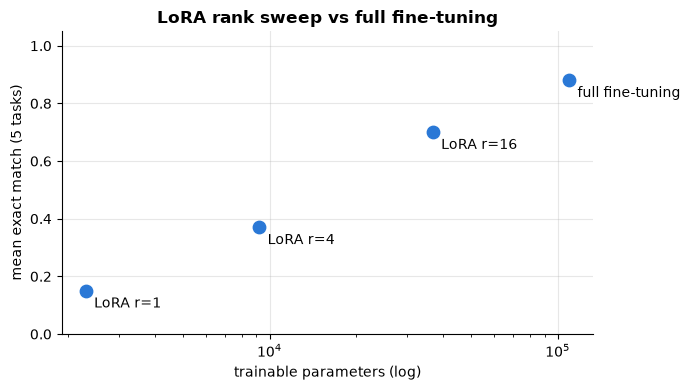

In [11]:
t0 = time.time()
rank_rows = [{"method": "full fine-tuning", "trainable params": n_params(base), "mean EM": full_em.mean(),
              "held-out perplexity": perplexity(sft_full), "train time (s)": sft_time}]
lora_models = {4: lora4}
for r in [1, 4, 16]:
    if r not in lora_models:
        m = add_lora(fresh_base(), r=r)
        _, tt = train_sft(m, lr=5e-3)
        lora_models[r] = m
    else:
        tt = lora_time
    m = lora_models[r]
    rank_rows.append({"method": f"LoRA r={r}", "trainable params": n_params(m, trainable=True),
                      "mean EM": exact_match_by_task(m).mean(), "held-out perplexity": perplexity(m), "train time (s)": tt})
rank_table = pd.DataFrame(rank_rows)
rank_table["% of model"] = 100 * rank_table["trainable params"] / n_params(base)
print(f"Rank sweep: {time.time() - t0:.0f} s  (base model held-out perplexity: {base_ppl:.2f})")
print(rank_table.round(3).to_string(index=False))

fig, ax = plt.subplots(figsize=(7, 4))
ax.scatter(rank_table["trainable params"], rank_table["mean EM"], s=80, color=PALETTE[0])
for _, row in rank_table.iterrows():
    ax.annotate(row["method"], (row["trainable params"], row["mean EM"]), textcoords="offset points", xytext=(6, -12))
ax.set_xscale("log"); ax.set_xlabel("trainable parameters (log)"); ax.set_ylabel("mean exact match (5 tasks)")
ax.set_ylim(0, 1.05); ax.set_title("LoRA rank sweep vs full fine-tuning"); plt.tight_layout(); plt.show()

**What just happened?** Compare the rows of the table:
- **Quality grows with rank.** Rank 1 (about 2% of the parameters) learns only part of the tasks in 400 steps; rank 16 gets much closer to full fine-tuning. In this tiny model LoRA also needs a larger learning rate than full fine-tuning. On real LLMs, ranks of 8–64 are usually enough for instruction tuning, because adapting a model that already knows the language needs only a low-rank change (the "intrinsic dimension" argument of the LoRA paper).
- **The perplexity column is a warning.** Every variant that learned the tasks also damaged the original skill (perplexity on held-out base text rose well above the base model's). Biderman et al. (2024), *"LoRA Learns Less and Forgets Less"*, found that on 7B models LoRA forgets less than full fine-tuning. Our toy model does **not** reproduce that: a rank-4 change to every layer of a 2-layer, 64-wide network is a large relative change, and the never-seen special tokens have frozen random embeddings that the adapters must work around. The lesson: measure forgetting in your own setting instead of assuming it. Section 5 shows a fix that does work here.

**Memory arithmetic (why LoRA matters on real models).** Fine-tuning a 7B-parameter model fully with Adam in mixed precision needs roughly 16 bytes per parameter (weights, gradients, two Adam moments, master weights) ≈ 112 GB. With LoRA, gradients and optimiser state exist only for the adapter (≪ 1% of parameters), and with **QLoRA** (Dettmers et al., 2023) the frozen base is stored in 4-bit NF4 (≈ 3.5 GB for 7B), which is why a 7B model can be fine-tuned on one consumer GPU.

> 🎓 **Exam / interview tip:** "Why initialise B to zero and not A?" So that training starts exactly from the pre-trained model ($\Delta W = 0$) while gradients still flow: $\partial L/\partial B = (\partial L/\partial h)\,(Ax)^\top \neq 0$ because $A \neq 0$. If both were zero, both gradients would be zero forever.

## 5. Catastrophic forgetting and replay mixing

> 💬 **In plain English:** training on a new skill can make the model worse at its old one; mixing in some old data prevents that.

**Catastrophic forgetting** (McCloskey & Cohen, 1989): training a network on a new task overwrites the weights that encoded old skills. For LLMs it shows up as worse general language modelling, lost knowledge or broken formats after fine-tuning. We measure it as the **perplexity on held-out pre-training text**, before and after.

Mitigations:
- **Replay (rehearsal) mixing:** keep a fraction of each batch from the original data distribution. We mix 25% plain-text rows into every SFT batch.
- **Parameter-efficient methods** (LoRA) limit how far the weights can move.
- **Regularisation towards the old weights** (e.g. EWC, Kirkpatrick et al., 2017) and lower learning rates or fewer steps.

Replay run: 26 s
                    model  held-out perplexity (lower = better)  mean EM on new tasks
base (before fine-tuning)                                 1.695                  0.00
                 full SFT                                25.833                  0.88
    full SFT + 25% replay                                 1.723                  0.58
                 LoRA r=4                                19.305                  0.37


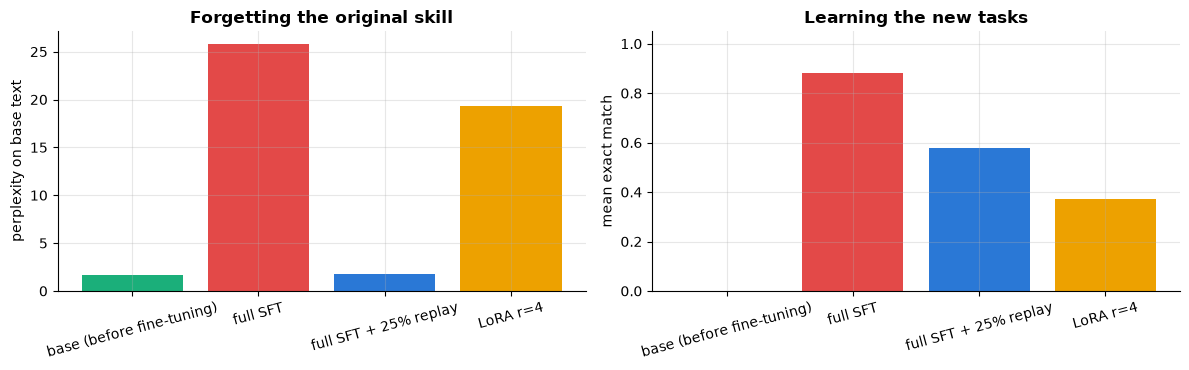

Full SFT model continues 'on 2021-': on 2021-1li, nice then.<end>e town<end>n<end>ar.<end>om<end>ne rard<end><end>or rests<end>g<end>5<end><end><end>5<end> r


In [12]:
t0 = time.time()
sft_replay = fresh_base()
_, replay_time = train_sft(sft_replay, steps=533, replay_frac=0.25)    # 533 x 24 = 400 x 32 instruction rows: same SFT data seen
forget = pd.DataFrame({
    "model": ["base (before fine-tuning)", "full SFT", "full SFT + 25% replay", "LoRA r=4"],
    "held-out perplexity (lower = better)": [base_ppl, perplexity(sft_full), perplexity(sft_replay), perplexity(lora4)],
    "mean EM on new tasks": [base_em.mean(), full_em.mean(), exact_match_by_task(sft_replay).mean(), lora4_em.mean()]})
print(f"Replay run: {replay_time:.0f} s")
print(forget.round(3).to_string(index=False))
fig, axes = plt.subplots(1, 2, figsize=(12, 3.8))
axes[0].bar(forget["model"], forget.iloc[:, 1], color=[PALETTE[2], PALETTE[7], PALETTE[0], PALETTE[3]])
axes[0].set_ylabel("perplexity on base text"); axes[0].set_title("Forgetting the original skill"); axes[0].tick_params(axis="x", rotation=15)
axes[1].bar(forget["model"], forget.iloc[:, 2], color=[PALETTE[2], PALETTE[7], PALETTE[0], PALETTE[3]])
axes[1].set_ylabel("mean exact match"); axes[1].set_title("Learning the new tasks"); axes[1].set_ylim(0, 1.05); axes[1].tick_params(axis="x", rotation=15)
plt.tight_layout(); plt.show()
print("Full SFT model continues 'on 2021-':", continue_text(sft_full, "on 2021-", 60))

**What just happened?** Full SFT learned the new tasks, but its perplexity on the original text went up many times over: it forgot much of how to *write* the language, as the garbled continuation shows. The SFT data contains only `<user>…<asst>…` sequences, so nothing in training keeps the model good at plain text. Mixing 25% replay rows into each batch keeps the perplexity at the base model's level. The price, for the same amount of instruction data, is slower progress on the new tasks (compare the exact-match column); in practice you train a little longer. LoRA r=4, without replay, forgets too in this tiny model. That is why production SFT mixes in general instruction data and pre-training-style text.

> ⚠️ **Common mistake:** evaluating a fine-tuned model only on the new task. Always keep a **regression set** for the old capabilities (here, base-text perplexity) and track it (see [`22_llm_evaluation_hands_on`](22_llm_evaluation_hands_on.ipynb), section 7).

## 6. DPO from scratch

> 💬 **In plain English:** show the model pairs of answers ('this one is better') and nudge it towards the better kind, without drifting too far from where it started.

**Direct Preference Optimization** (Rafailov et al., 2023) learns from **preference pairs** $(x, y_w, y_l)$: for prompt $x$, answer $y_w$ ("chosen", the winner) is preferred to $y_l$ ("rejected", the loser). RLHF would first fit a reward model and then run PPO (see [`11_Reinforcement_Learning/10`](../11_Reinforcement_Learning/10_deep_rl_on_cpu.ipynb)). DPO shows that the KL-regularised RLHF objective has a closed-form optimal policy, so the same goal can be reached with a simple classification-style loss:

$$\mathcal L_{\text{DPO}} = -\log\sigma\Big(\beta\big[\underbrace{\log\pi_\theta(y_w\mid x) - \log\pi_{\text{ref}}(y_w\mid x)}_{\text{implicit reward of } y_w} - \underbrace{\big(\log\pi_\theta(y_l\mid x) - \log\pi_{\text{ref}}(y_l\mid x)\big)}_{\text{implicit reward of } y_l}\big]\Big).$$

- $\pi_{\text{ref}}$ is a **frozen copy** of the SFT model (the "reference-model trick"). The loss only cares about how much the policy has moved *relative to the reference*, which acts like the KL penalty in RLHF.
- **β** sets the strength of that tether. A small β lets the policy move far from the reference; a large β keeps it close.
- $\log\pi(y\mid x)$ is the **sum of log-probabilities of the answer tokens** (prompt tokens masked, as in SFT).

Our preference data: for `greet: <name>`, chosen = `hello <name>, nice to meet you.` and rejected = `go away <name>.` We train on 14 names and test on the 6 held-out names.

In [13]:
def answer_logprob(model, pairs):
    """Sum of log p(answer tokens + <end> | prompt) for each (prompt, answer) pair."""
    X, Y = build_batch(pairs)
    logp = F.log_softmax(model(X), dim=-1)
    mask = Y != -100
    token_lp = logp.gather(-1, Y.clamp(min=0).unsqueeze(-1)).squeeze(-1) * mask
    return token_lp.sum(1)

train_names, test_names = NAMES[:14], NAMES[14:]
pref = lambda names: ([(f"greet: {n}", POLITE.format(n=n)) for n in names], [(f"greet: {n}", RUDE.format(n=n)) for n in names])

@torch.no_grad()
def preference_stats(model, ref, names):
    chosen, rejected = pref(names)
    lc, lr = answer_logprob(model, chosen), answer_logprob(model, rejected)
    rc, rr = lc - answer_logprob(ref, chosen), lr - answer_logprob(ref, rejected)
    outs = [generate(model, f"greet: {n}") for n in names]
    return {"P(chosen) vs rejected": torch.sigmoid(lc - lr).mean().item(),       # the model's own preference
            "polite greedy outputs": np.mean([o.startswith("hello") for o in outs]),
            "implicit reward margin": (rc - rr).mean().item(),
            "Δ log p(chosen)": rc.mean().item(), "Δ log p(rejected)": rr.mean().item()}

def train_dpo(policy, ref, beta, steps=60, lr=5e-4, batch_size=8, seed=0):
    rng = random.Random(seed); opt = torch.optim.AdamW(policy.parameters(), lr=lr); log = []
    for p in ref.parameters():
        p.requires_grad = False
    policy.train()
    for step in range(steps + 1):
        names = rng.sample(train_names, batch_size)
        chosen, rejected = pref(names)
        pc, pr = answer_logprob(policy, chosen), answer_logprob(policy, rejected)
        with torch.no_grad():
            rc, rr = answer_logprob(ref, chosen), answer_logprob(ref, rejected)
        margin = (pc - rc) - (pr - rr)
        loss = -F.logsigmoid(beta * margin).mean()
        opt.zero_grad(); loss.backward(); opt.step()
        log.append({"step": step, "loss": loss.item(), "margin": margin.mean().item(),
                    "Δ log p(chosen)": (pc - rc).mean().item(), "Δ log p(rejected)": (pr - rr).mean().item()})
    policy.eval()
    return pd.DataFrame(log)

reference = copy.deepcopy(sft_full).eval()                  # frozen SFT model = pi_ref (also the starting policy)
before = preference_stats(sft_full, reference, test_names)
t0 = time.time()
dpo_runs = {}
for beta in [0.05, 0.5, 2.0]:
    policy = copy.deepcopy(sft_full)
    log = train_dpo(policy, reference, beta)
    dpo_runs[beta] = (policy, log)
print(f"DPO β sweep: {time.time() - t0:.0f} s")
rows = {"SFT model (before DPO)": before}
for beta, (policy, _) in dpo_runs.items():
    stats = preference_stats(policy, reference, test_names)
    stats["other tasks mean EM"] = exact_match_by_task(policy).mean()
    rows[f"after DPO, β={beta}"] = stats
rows["SFT model (before DPO)"]["other tasks mean EM"] = full_em.mean()
dpo_table = pd.DataFrame(rows).T
print("Measured on the 6 HELD-OUT names:")
print(dpo_table.round(3).to_string())

DPO β sweep: 6 s


Measured on the 6 HELD-OUT names:
                        P(chosen) vs rejected  polite greedy outputs  implicit reward margin  Δ log p(chosen)  Δ log p(rejected)  other tasks mean EM
SFT model (before DPO)                  0.504                  0.500                   0.000            0.000              0.000                 0.88
after DPO, β=0.05                       1.000                  0.333                 168.760          -22.241           -191.001                 0.08
after DPO, β=0.5                        1.000                  0.833                  22.409           -0.261            -22.670                 0.58
after DPO, β=2.0                        1.000                  1.000                   8.977            0.623             -8.354                 0.76


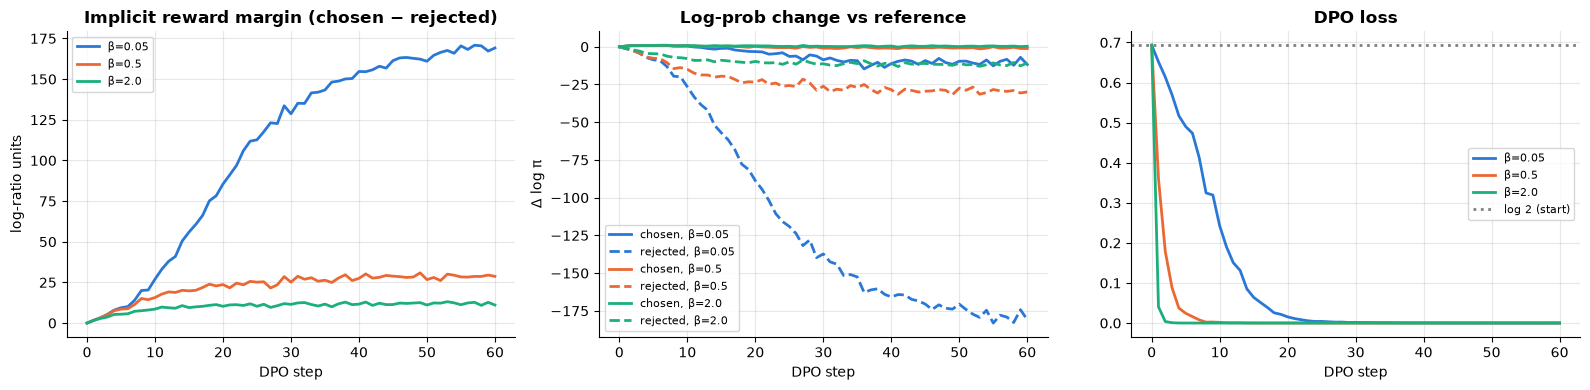

Greedy greetings for held-out names after DPO (β=0.5): ['hello  ana.', 'hello kai, nice to meet you.', 'hello ivy, nice to meet you.']


In [14]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4))
for i, (beta, (_, log)) in enumerate(dpo_runs.items()):
    axes[0].plot(log["step"], log["margin"], label=f"β={beta}", color=PALETTE[i])
    axes[1].plot(log["step"], log["Δ log p(chosen)"], label=f"chosen, β={beta}", color=PALETTE[i])
    axes[1].plot(log["step"], log["Δ log p(rejected)"], "--", label=f"rejected, β={beta}", color=PALETTE[i])
    axes[2].plot(log["step"], log["loss"], label=f"β={beta}", color=PALETTE[i])
axes[0].set_title("Implicit reward margin (chosen − rejected)"); axes[0].set_ylabel("log-ratio units")
axes[1].set_title("Log-prob change vs reference"); axes[1].set_ylabel("Δ log π")
axes[2].set_title("DPO loss"); axes[2].axhline(math.log(2), color="grey", ls=":", label="log 2 (start)")
for ax in axes:
    ax.set_xlabel("DPO step"); ax.legend(fontsize=8)
plt.tight_layout(); plt.show()
print("Greedy greetings for held-out names after DPO (β=0.5):", [generate(dpo_runs[0.5][0], f"greet: {n}") for n in test_names[:3]])

**What just happened?** Read the table (held-out names, so this is generalisation, not memorisation):
- Before DPO the SFT model is torn between the two styles: its own probability of preferring the polite answer is close to 50%, as in the SFT data.
- After DPO the model's own preference probability goes to 1 for every β.
- The **β sweep** shows the tether at work: the loss starts at $\log 2$ (margin 0) for every β, but a small β must push the log-probabilities much further (bigger margin, bigger Δ log π) to get a small loss, so the policy moves much further from the reference. A large β reaches a low loss with a small move.
- Too far is harmful: with β = 0.05 the greedy greetings degenerate (only a third are clean polite sentences) and the other five tasks collapse. β = 2 gives clean polite greetings for every held-out name and keeps most of the other skills. This is the same trade-off as the KL penalty in RLHF.
- The middle plot shows a well-known DPO behaviour: the **rejected** log-prob drops sharply, and the **chosen** log-prob can also go *down* a little. DPO only optimises the *difference*, so it can achieve its goal by making the rejected answer much less likely rather than the chosen one more likely.
- The last column measures that collateral damage: exact match on the other five tasks after DPO, compared with the SFT model's. Even the best β costs some accuracy, because DPO trained on greetings only; real preference datasets cover many tasks for this reason.

> ⚠️ **Common mistake:** forgetting to freeze the reference model, or computing its log-probs with gradients on. The reference must stay the SFT model; if it moves with the policy, the margin is always 0 and nothing is learned.

> 🎓 **Exam / interview tip:** "DPO vs RLHF-PPO?" DPO needs no reward model and no sampling during training (it is offline, a supervised-style loss on fixed pairs), so it is simpler and more stable. RLHF with PPO is online: it samples new answers and can improve beyond the preference data, at much higher cost and complexity.

## 7. Overfitting, early stopping and checkpointing

> 💬 **In plain English:** with little data the model starts memorising; watch a validation set and keep the best saved version.

With small fine-tuning sets, models memorise quickly: the training loss keeps falling while the **validation loss** turns up. **Early stopping** keeps the checkpoint with the best validation loss. **Checkpointing** means saving the weights (and in real training, the optimiser state and step count) to disk so you can resume or roll back.

We fine-tune on only **100 examples** with a validation set of 300 and save the best checkpoint to a temporary folder.

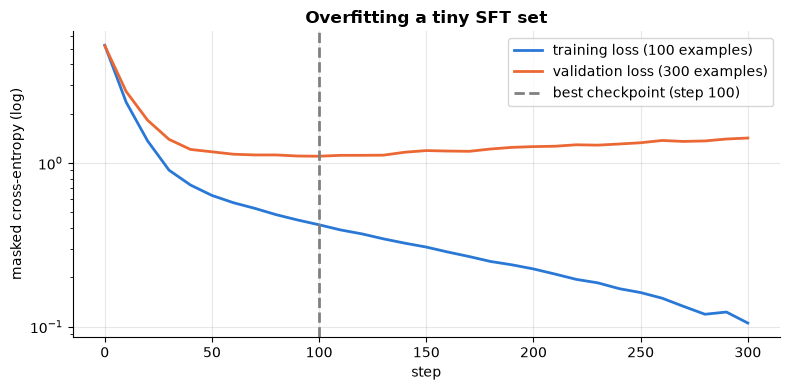

Checkpoint file: 1311 KB (weights + Adam state). Best step 100, val loss 1.099; final val loss 1.420


Validation exact match: best checkpoint 0.09 vs final model 0.12


In [15]:
small_pairs = [make_example(random.Random(100 + i), TASKS[i % 5]) for i in range(100)]
val_pairs = [make_example(random.Random(5000 + i), TASKS[i % 5]) for i in range(300)]
Xs, Ys = build_batch(small_pairs); Xv, Yv = build_batch(val_pairs)

@torch.no_grad()
def masked_loss(model, X, Y):
    model.eval(); l = F.cross_entropy(model(X).flatten(0, 1), Y.flatten(), ignore_index=-100).item(); model.train(); return l

ckpt_dir = tempfile.mkdtemp()
try:
    model = fresh_base(); model.train()
    opt = torch.optim.AdamW(model.parameters(), lr=1e-3)
    gen = torch.Generator().manual_seed(0)
    best_val, best_step, history = float("inf"), -1, []
    for step in range(301):
        idx = torch.randint(len(Xs), (16,), generator=gen)
        loss = F.cross_entropy(model(Xs[idx]).flatten(0, 1), Ys[idx].flatten(), ignore_index=-100)
        opt.zero_grad(); loss.backward(); opt.step()
        if step % 10 == 0:
            tr, va = masked_loss(model, Xs, Ys), masked_loss(model, Xv, Yv)
            history.append((step, tr, va))
            if va < best_val:                                               # new best: save a checkpoint
                best_val, best_step = va, step
                torch.save({"step": step, "model": model.state_dict(), "optimizer": opt.state_dict(), "val_loss": va},
                           os.path.join(ckpt_dir, "best.pt"))
    final_model = model.eval()
    ckpt = torch.load(os.path.join(ckpt_dir, "best.pt"))
    best_model = TinyGPT(); best_model.load_state_dict(ckpt["model"]); best_model.eval()
    ckpt_kb = os.path.getsize(os.path.join(ckpt_dir, "best.pt")) / 1024
finally:
    shutil.rmtree(ckpt_dir)                                                 # clean up the temporary folder

h = np.array(history)
plt.figure(figsize=(8, 4))
plt.plot(h[:, 0], h[:, 1], label="training loss (100 examples)"); plt.plot(h[:, 0], h[:, 2], label="validation loss (300 examples)")
plt.axvline(best_step, color="grey", ls="--", label=f"best checkpoint (step {best_step})")
plt.yscale("log"); plt.xlabel("step"); plt.ylabel("masked cross-entropy (log)"); plt.title("Overfitting a tiny SFT set"); plt.legend()
plt.tight_layout(); plt.show()
val_em = lambda m: np.mean([generate(m, p) == a for p, a in val_pairs[:100]])
print(f"Checkpoint file: {ckpt_kb:.0f} KB (weights + Adam state). Best step {best_step}, val loss {best_val:.3f}; final val loss {h[-1, 2]:.3f}")
print(f"Validation exact match: best checkpoint {val_em(best_model):.2f} vs final model {val_em(final_model):.2f}")

**What just happened?** The training loss on the 100 examples keeps falling towards zero (memorisation), while the validation loss bottoms out and then rises: classic overfitting. The checkpoint saved at the best validation loss is the one early stopping keeps, and we restored it from disk. Notice, though, that the final model's validation exact match is about the same or even slightly higher: the validation *loss* rises mainly because the model becomes over-confident on its mistakes, which exact match does not see. Choose the early-stopping criterion that matches what you care about (the task metric, if it is cheap enough to compute). Note the checkpoint size: Adam's two moment buffers make the file about three times larger than the weights alone.

> 🎓 **Exam / interview tip:** with tiny fine-tuning sets, prefer fewer epochs, a lower learning rate, LoRA, and early stopping on a held-out set that matches the deployment distribution, and evaluate with the *task metric*, not only the loss.

## 8. [optional] The same with `peft` and `trl`

> 💬 **In plain English:** the same ideas with the standard Hugging Face libraries, on a tiny test model.

In practice you use Hugging Face **`peft`** (LoRA and friends) and **`trl`** (`SFTTrainer`, `DPOTrainer`). This cell uses `trl-internal-testing/tiny-Qwen2ForCausalLM-2.5`, a *random-weight* test model with the real Qwen2 architecture and tokenizer (about 2.4 M parameters, almost all in the 152k-token embedding). It shows the mechanics only: the outputs are meaningless. The cell runs only if the model is already in your local Hugging Face cache and `peft`/`trl` are installed; otherwise it prints a message and skips.

In [16]:
HF_MODEL = "trl-internal-testing/tiny-Qwen2ForCausalLM-2.5"
cache_dir = os.path.join(os.path.expanduser("~"), ".cache", "huggingface", "hub", "models--" + HF_MODEL.replace("/", "--"))
if not os.path.isdir(cache_dir):
    print(f"{HF_MODEL} is not in the local Hugging Face cache: skipping the optional peft/trl section.")
else:
    try:
        os.environ["HF_HUB_OFFLINE"] = "1"                    # the model is cached: never touch the network
        os.environ["TRANSFORMERS_VERBOSITY"] = "error"
        import logging, warnings
        import transformers, peft, trl, datasets
        transformers.utils.logging.set_verbosity_error(); transformers.utils.logging.disable_progress_bar()
        datasets.disable_progress_bars(); datasets.logging.set_verbosity_error()
        logging.getLogger("trl").setLevel(logging.ERROR)
        from transformers import AutoTokenizer, AutoModelForCausalLM, PrinterCallback
        from peft import LoraConfig, get_peft_model
        HF_OK = True
    except ImportError as err:
        HF_OK = False
        print("Optional libraries missing, skipping:", err)
    if HF_OK:
        tok = AutoTokenizer.from_pretrained(HF_MODEL)
        msgs = [{"role": "user", "content": "date: 2026-10-27"}, {"role": "assistant", "content": "27/10/2026"}]
        print("Real chat template (Qwen2.5, ChatML):\n" + tok.apply_chat_template(msgs, tokenize=False))
        print("Generation prompt:\n" + tok.apply_chat_template(msgs[:1], tokenize=False, add_generation_prompt=True))

        hf_model = AutoModelForCausalLM.from_pretrained(HF_MODEL, dtype=torch.float32)
        cfg = LoraConfig(r=8, lora_alpha=16, target_modules=["q_proj", "v_proj"], lora_dropout=0.0)
        peft_model = get_peft_model(hf_model, cfg)
        trainable, total = peft_model.get_nb_trainable_parameters()
        print(f"peft LoRA r=8 on q_proj, v_proj: {trainable:,} trainable of {total:,} parameters ({trainable / total:.3%})")

        # Assistant-only loss masking with the real template: label -100 for every token of the generation prompt
        prompt_ids = tok.apply_chat_template(msgs[:1], add_generation_prompt=True, tokenize=True, return_dict=True)["input_ids"]
        full_ids = tok.apply_chat_template(msgs, tokenize=True, return_dict=True)["input_ids"]
        assert full_ids[:len(prompt_ids)] == prompt_ids               # the prompt is a prefix of the full conversation
        labels = [-100] * len(prompt_ids) + full_ids[len(prompt_ids):]
        ids_t, lab_t = torch.tensor([full_ids]), torch.tensor([labels])
        opt_hf = torch.optim.AdamW([p for p in peft_model.parameters() if p.requires_grad], lr=1e-2)
        losses = []
        for _ in range(5):                                            # a few steps on one example (HF shifts labels internally)
            out = peft_model(input_ids=ids_t, labels=lab_t)
            opt_hf.zero_grad(); out.loss.backward(); opt_hf.step(); losses.append(round(out.loss.item(), 4))
        print("manual LoRA steps, loss:", losses, f"| {len(prompt_ids)} of {len(full_ids)} label positions masked")
        with torch.no_grad():
            before_merge = peft_model(input_ids=ids_t).logits
            merged = peft_model.merge_and_unload()                    # fold B@A into the base weights
            after_merge = merged(input_ids=ids_t).logits
        print("merge_and_unload keeps outputs identical:", torch.allclose(before_merge, after_merge, atol=1e-4))

        # trl: SFTTrainer and DPOTrainer for 2 steps each (mechanics only)
        from datasets import Dataset
        from trl import SFTConfig, SFTTrainer, DPOConfig, DPOTrainer
        out_dir = tempfile.mkdtemp()
        try:
            common = dict(output_dir=out_dir, max_steps=2, per_device_train_batch_size=4, report_to=[], logging_steps=1,
                          use_cpu=True, save_strategy="no", disable_tqdm=True, seed=0)
            sft_ds = Dataset.from_list([{"messages": [{"role": "user", "content": p}, {"role": "assistant", "content": a}]} for p, a in train_pairs[:16]])
            sft_tr = SFTTrainer(model=AutoModelForCausalLM.from_pretrained(HF_MODEL, dtype=torch.float32),
                                args=SFTConfig(assistant_only_loss=True, **common), train_dataset=sft_ds, processing_class=tok,
                                peft_config=LoraConfig(r=8, lora_alpha=16, target_modules=["q_proj", "v_proj"]))
            sft_tr.remove_callback(PrinterCallback)
            sft_res = sft_tr.train()
            dpo_ds = Dataset.from_list([{"prompt": [{"role": "user", "content": f"greet: {n}"}],
                                         "chosen": [{"role": "assistant", "content": POLITE.format(n=n)}],
                                         "rejected": [{"role": "assistant", "content": RUDE.format(n=n)}]} for n in train_names[:8]])
            dpo_tr = DPOTrainer(model=AutoModelForCausalLM.from_pretrained(HF_MODEL, dtype=torch.float32),
                                args=DPOConfig(beta=0.1, **common), train_dataset=dpo_ds, processing_class=tok,
                                peft_config=LoraConfig(r=8, lora_alpha=16, target_modules=["q_proj", "v_proj"]))
            dpo_tr.remove_callback(PrinterCallback)
            dpo_res = dpo_tr.train()
            first = dpo_tr.state.log_history[0]
        finally:
            shutil.rmtree(out_dir)
        print(f"trl SFTTrainer (assistant_only_loss=True): 2 steps, loss {sft_res.training_loss:.3f} (≈ ln(vocab) = {math.log(len(tok)):.3f}: random weights)")
        print(f"trl DPOTrainer: 2 steps, loss {dpo_res.training_loss:.4f} (starts at ln 2 = {math.log(2):.4f}); logged keys include",
              sorted(k for k in first if k.startswith("rewards/")))

Real chat template (Qwen2.5, ChatML):
<|im_start|>system
You are Qwen, created by Alibaba Cloud. You are a helpful assistant.<|im_end|>
<|im_start|>user
date: 2026-10-27<|im_end|>
<|im_start|>assistant
27/10/2026<|im_end|>

Generation prompt:
<|im_start|>system
You are Qwen, created by Alibaba Cloud. You are a helpful assistant.<|im_end|>
<|im_start|>user
date: 2026-10-27<|im_end|>
<|im_start|>assistant

peft LoRA r=8 on q_proj, v_proj: 448 trainable of 2,435,464 parameters (0.018%)


manual LoRA steps, loss: [11.9322, 11.93, 11.9277, 11.926, 11.9242] | 42 of 54 label positions masked
merge_and_unload keeps outputs identical: True


trl SFTTrainer (assistant_only_loss=True): 2 steps, loss 11.934 (≈ ln(vocab) = 11.929: random weights)
trl DPOTrainer: 2 steps, loss 0.6931 (starts at ln 2 = 0.6931); logged keys include ['rewards/accuracies', 'rewards/chosen', 'rewards/margins', 'rewards/rejected']


**What just happened?** (If the cell ran.) The real Qwen chat template adds a default system message and uses `<|im_start|>`/`<|im_end|>` markers. The same assistant-only masking idea applies: the generation prompt is a prefix of the full conversation, and those positions get −100 (`trl` does this for you with `assistant_only_loss=True`). `peft` reports the trainable fraction, and `merge_and_unload()` folds the adapter into the weights exactly as our `merge()` did. `trl`'s DPO loss starts at $\ln 2$, like ours, and it logs the same quantities we plotted (`rewards/chosen`, `rewards/rejected`, `rewards/margins`, `rewards/accuracies`). The losses are large because the test model has random weights.

## 9. Summary table

> 💬 **In plain English:** one table comparing the fine-tuning options.

| Method | What is trained | Data | Memory / cost | Forgetting risk | When to use |
|---|---|---|---|---|---|
| Prompting / few-shot | nothing | a few examples in the prompt | none | none | first thing to try |
| Full SFT | all weights | (instruction, answer) pairs | highest (gradients + Adam state for all) | high (needs replay, low lr) | big behaviour change, enough data and compute |
| LoRA | low-rank adapters $A, B$ | same as SFT | small (adapter only); merge for free inference | lower | default for most custom fine-tunes |
| QLoRA | LoRA on a 4-bit frozen base | same as SFT | smallest | lower | large models on one GPU |
| DPO | all weights or LoRA | preference pairs | 2 models (policy + frozen reference) | moderate (β controls drift) | style, safety, helpfulness preferences |
| RLHF (PPO) | policy + value + reward model | preferences → reward model, online samples | highest (4 models) | controlled by KL penalty | when online exploration beyond the data matters |

## 10. 🔗 How this connects to modern AI

> 💬 **In plain English:** how these techniques are used to build and serve real chat models.

- **Instruction tuning** (FLAN, InstructGPT, Llama-Instruct) is section 3 at scale: millions of (instruction, answer) pairs with chat templates and assistant-only loss masking.
- **LoRA adapters in production:** one base model in memory serves many customers' adapters (multi-LoRA serving in vLLM or LoRAX), using the merge/unmerge algebra of section 4. See [`05_Deep_Learning/12_advanced_peft`](../05_Deep_Learning/12_advanced_peft.ipynb) for DoRA, AdaLoRA and other variants, and [`13_inference_optimization`](13_inference_optimization.ipynb) for serving.
- **Preference optimisation:** DPO and its variants (IPO, KTO, ORPO, SimPO) are compared in [`12_alignment_techniques`](12_alignment_techniques.ipynb); RLHF uses PPO from [`11_Reinforcement_Learning/10`](../11_Reinforcement_Learning/10_deep_rl_on_cpu.ipynb); reasoning models use RL with verifiable rewards ([`18_reasoning_models`](18_reasoning_models.ipynb)).
- **Forgetting and regression testing:** every fine-tune needs before/after evaluation on old capabilities. The next notebook, [`22_llm_evaluation_hands_on`](22_llm_evaluation_hands_on.ipynb), builds that evaluation harness.
- **Small models:** fine-tuned small language models often beat prompted large ones on narrow tasks at a fraction of the cost ([`05_slms`](05_slms/)).

## 11. Recap

> 💬 **In plain English:** key points, practice and further reading.

- A **chat template** fixes the exact token layout; train and serve with the same one.
- **Loss masking** puts −100 on prompt and padding labels so the model learns only to answer; check it with asserts, and watch the off-by-one.
- **Full SFT** learns fast but can **forget** the base skill; **replay mixing** largely prevents that.
- **LoRA** learns a low-rank update $\frac{\alpha}{r}BA$ with $B = 0$ at init; it trains a few percent of the parameters, merges for free, and forgets less.
- **DPO** turns preference pairs into a logistic loss on log-probability ratios against a **frozen reference**; **β** controls how far the policy may drift.
- Use a **validation set**, **early stopping** and **checkpoints**; evaluate with the task metric.

## Practice problems

**1. (Conceptual, easy)** A prompt (including `<asst>`) has $P$ tokens. Exactly how many label positions must be masked, and what goes wrong if you mask $P$?

<details><summary>Show solution</summary>

Input and label sequences are shifted by one: position $t$ predicts token $t+1$. The prompt `<user>date: 2026-10-27<end><asst>` has $P$ tokens, at positions $0 \dots P-1$. The labels at positions $0 \dots P-2$ are prompt tokens (mask them). Position $P-1$ is `<asst>`, and its label is the first answer token, which must be kept. So exactly $P-1$ labels are masked. Masking $P$ would drop the first answer token from the loss, and the model would never learn how to start its answer.

</details>

**2. (Calculation, easy)** How many trainable parameters does LoRA with $r = 16$ add to one 4096×4096 projection? What fraction of the full matrix is that? How many for 32 layers × 4 attention projections?

<details><summary>Show solution</summary>

Full: $d_{in} d_{out} = 4096 \times 4096 = 16{,}777{,}216$. LoRA: $r(d_{in} + d_{out}) = 16 \times 8192 = 131{,}072$, i.e. 0.78%. With 32 layers × 4 attention matrices: $128 \times 131{,}072 \approx 16.8$ M adapter parameters (about 34 MB in fp16) vs $128 \times 16.8$ M ≈ 2.1 B for those matrices in full.

</details>

**3. (Coding, easy)** Using `LoRALinear`, give $B$ random values, then verify that merge and unmerge preserve the outputs, and that the update $\frac{\alpha}{r}BA$ has rank at most $r$.

<details><summary>Show solution</summary>

```python
x = torch.randn(3, 64)
layer = LoRALinear(nn.Linear(64, 64), r=4, alpha=8)
nn.init.normal_(layer.B)                         # pretend it has been trained
y1 = layer(x)
layer.merge();   y2 = layer(x)
layer.unmerge(); y3 = layer(x)
print(torch.allclose(y1, y2, atol=1e-5), torch.allclose(y1, y3, atol=1e-5))   # True True
# Rank check: the update has rank <= r
print(torch.linalg.matrix_rank(layer.scale * layer.B @ layer.A).item())        # 4
```

</details>

**4. (Derivation, medium)** Derive the gradient of the DPO loss with respect to θ. Which preference pairs get the largest weight?

<details><summary>Show solution</summary>

With margin $m = \beta[(\log\pi_w - \log\pi^{ref}_w) - (\log\pi_l - \log\pi^{ref}_l)]$, the loss is $-\log\sigma(m)$, and $\partial(-\log\sigma(m))/\partial m = -(1 - \sigma(m)) = -\sigma(-m)$. So

$$\nabla_\theta \mathcal L = -\beta\,\sigma(-m)\,\big[\nabla_\theta\log\pi_\theta(y_w\mid x) - \nabla_\theta\log\pi_\theta(y_l\mid x)\big].$$

Gradient descent increases $\log\pi(y_w)$ and decreases $\log\pi(y_l)$, weighted by $\sigma(-m)$: pairs the model already orders correctly (large $m$) get almost no weight; pairs it gets wrong get the most. At the start ($\pi_\theta = \pi_{ref}$, $m = 0$) the weight is $\sigma(0) = 0.5$ and the loss is $\log 2$.

</details>

**5. (Coding, easy)** Write `dpo_loss(pc, pr, rc, rr, beta)` and check it equals $\ln 2$ when the policy equals the reference.

<details><summary>Show solution</summary>

```python
def dpo_loss(pc, pr, rc, rr, beta):
    return -F.logsigmoid(beta * ((pc - rc) - (pr - rr))).mean()

z = torch.tensor([-5.0])
print(dpo_loss(z, z, z, z, 0.1).item(), math.log(2))                 # 0.6931 0.6931 (policy == reference)
print(dpo_loss(torch.tensor([-4.0]), torch.tensor([-6.0]), z, z, 0.1).item())   # margin 2*0.1=0.2 -> 0.598
```

</details>

**6. (Coding, medium)** Reduce forgetting with an L2 penalty that pulls the weights towards the pre-trained ones (a simplified EWC). How does the penalty strength trade off forgetting vs learning?

<details><summary>Show solution</summary>

```python
def train_sft_with_ewc(model, ref_state, lam=0.003, steps=400, lr=2e-3):
    """L2 pull towards the pre-trained weights (a simplified EWC with a uniform Fisher)."""
    opt = torch.optim.AdamW(model.parameters(), lr=lr); gen = torch.Generator().manual_seed(0)
    anchor = {k: v.clone() for k, v in ref_state.items()}
    for step in range(steps):
        idx = torch.randint(len(X_train), (32,), generator=gen)
        loss = F.cross_entropy(model(X_train[idx]).flatten(0, 1), Y_train[idx].flatten(), ignore_index=-100)
        loss = loss + lam * sum(((p - anchor[n]) ** 2).sum() for n, p in model.named_parameters())
        opt.zero_grad(); loss.backward(); opt.step()
    return model.eval()

for lam in [0.003, 0.03, 0.3]:
    m = train_sft_with_ewc(fresh_base(), BASE_STATE, lam=lam)
    print(lam, round(perplexity(m), 2), exact_match_by_task(m).mean())
# In our run: 0.003 -> perplexity ~8.7, EM ~0.74 | 0.03 -> ~3.5, ~0.25 | 0.3 -> ~2.1, ~0.03
# (no penalty: ~26 and 0.88; base model perplexity 1.69)
```
A larger penalty keeps the perplexity closer to the base model but learns the new tasks more slowly: a smooth trade-off. Compare with replay (section 5), which here kept the base perplexity *and* learned more. Real EWC weights each parameter's penalty by its Fisher information, so the parameters most important for the old task are protected most.

</details>

**7. (Design, hard)** Your company wants a 7B open model to fill in a JSON form from customer emails, in a polite house style, on one 24 GB GPU. Outline the data, method, hyperparameters, evaluation and serving plan.

<details><summary>Show solution</summary>

A strong answer covers: (1) **data**: a few thousand high-quality, deduplicated examples in the target format, with a held-out validation set and a regression set for general capabilities; (2) **method**: LoRA or QLoRA on the attention and MLP projections, r = 8–16, learning rate around 1e-4 to 2e-4, 1–3 epochs, early stopping on validation; mix in general instruction data (replay) if forgetting appears; (3) **template**: the base model's official chat template with assistant-only loss; (4) **evaluation**: task metric (exact match / F1 / judge), before vs after with bootstrap CIs, plus safety and regression suites (see [`22_llm_evaluation_hands_on`](22_llm_evaluation_hands_on.ipynb)); (5) **preferences**: if style or safety needs tuning, collect preference pairs and run DPO with β ≈ 0.1, checking the KL drift and regressions; (6) **serving**: merge the adapter or serve it with multi-LoRA.

</details>

## Further reading
- Hu et al. (2021), "LoRA: Low-Rank Adaptation of Large Language Models", arXiv:2106.09685.
- Dettmers et al. (2023), "QLoRA: Efficient Finetuning of Quantized LLMs", NeurIPS.
- Rafailov et al. (2023), "Direct Preference Optimization: Your Language Model is Secretly a Reward Model", NeurIPS.
- Ouyang et al. (2022), "Training language models to follow instructions with human feedback" (InstructGPT).
- Biderman et al. (2024), "LoRA Learns Less and Forgets Less", TMLR; Kirkpatrick et al. (2017), "Overcoming catastrophic forgetting in neural networks" (EWC), PNAS.
- Jurafsky & Martin, *Speech and Language Processing*, 3rd ed. draft, chapters on LLMs, instruction tuning and preference alignment (free online).
- Hugging Face [PEFT](https://huggingface.co/docs/peft) and [TRL](https://huggingface.co/docs/trl) documentation.

## Next notebook
➡️ [`22_llm_evaluation_hands_on.ipynb`](22_llm_evaluation_hands_on.ipynb): how to measure whether a model (or a fine-tune) is actually better, with metrics, judges, RAG metrics, statistics and regression tests.

In [17]:
print(f"Notebook finished in {time.time() - NOTEBOOK_START:.0f} s")

Notebook finished in 251 s
